# 4.2 Entity co-occurrence network

**Not a follower / user-user graph.** `IFB.db` has no follow, reply, or retweet-cascade edges.

Canonical key (one definition, used everywhere):
- **Node** = canonical entity name (category is a node attribute)
- **Edge** = unordered pair of two *different* names
- **edge_weight** = distinct posts containing both names (min 5)

Entities shorter than 3 characters are excluded. One row of `entity_network_edges.csv` = one graph edge. Combined graph: **1,076 nodes / 2,578 edges**. NER is **not** rerun.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

def find_root() -> Path:
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "outputs").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot find the project root (need outputs/ and src/). "
        "Open this notebook from the repo, from notebooks/, or from a guideline folder."
    )

ROOT = find_root()
OUT = ROOT / "outputs"
print("ROOT =", ROOT)
print("This notebook reads shipped CSVs and PNGs only.")
print("It does not open IFB.db, does not open any analysis database,")
print("and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.")


ROOT = C:\Users\yosef\OneDrive\שולחן העבודה\IFB-project
This notebook reads shipped CSVs and PNGs only.
It does not open IFB.db, does not open any analysis database,
and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.


edge rows 2578 node rows 1076
sum(degree)/2 2578.0
[embedded figure] entity_network_graph.png (498,085 bytes)
DONE network verification


,graph,n_nodes,n_edges,density,n_components,largest_component,average_degree,average_weighted_degree,clustering_coefficient,edge_key,min_entity_chars,min_edge_weight,note
0,combined_min_edge,1076,2578,0.004458,57,944,4.7918,67.2770,0.0101,"unordered (entity_a, entity_b) canonical names",3,5,"Entity co-occurrence, not a follower network"
1,keyword_only,646,1261,0.006053,52,500,3.9040,53.6409,0.0093,"unordered (entity_a, entity_b) canonical names",3,5,"Entity co-occurrence, not a follower network"
2,timeline_only_raw,547,1175,0.007868,40,463,4.2962,54.3218,0.0186,"unordered (entity_a, entity_b) canonical names",3,5,"Entity co-occurrence, not a follower network"
3,person_person,187,204,0.011730,32,96,2.1818,29.2193,0.0123,"unordered (entity_a, entity_b) canonical names",3,5,"Entity co-occurrence, not a follower network"
4,person_country,273,473,0.012740,22,228,3.4652,57.2088,0.0137,"unordered (entity_a, entity_b) canonical names",3,5,"Entity co-occurrence, not a follower network"
5,organization,295,374,0.008624,37,196,2.5356,34.3458,0.0249,"unordered (entity_a, entity_b) canonical names",3,5,"Entity co-occurrence, not a follower network"


,entity_a,entity_b,category_a,category_b,edge_weight,unique_posts,unique_users,keyword_post_count,timeline_raw_post_count,timeline_weighted_estimate,first_date,last_date,edge_key_note,mix_note
0,Florida,Tampa,location,location,509,509,3,506,3,177.44,2019-01-01T12:43:46,2023-10-05T08:59:05,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
1,Russia,Ukraine,country,country,347,347,175,166,181,10705.82,2020-06-27T19:39:51,2023-11-11T10:08:51,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
2,Donald Trump,Joe Biden,person,person,325,325,203,99,226,13367.49,2019-06-12T09:16:37,2023-11-20T11:52:09,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
3,Joe Biden,United States,person,country,228,228,136,85,143,8458.29,2012-10-12T01:57:03,2023-11-20T11:52:09,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
4,Donald Trump,United States,person,country,207,207,125,106,101,5974.06,2016-11-19T01:09:26,2023-11-20T11:52:09,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
5,Russia,United States,country,country,166,166,87,75,91,5382.48,2012-06-27T00:31:01,2023-11-10T22:54:26,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
6,Donald Trump,GOP,person,organization,160,160,79,81,79,4672.73,2019-04-21T18:35:18,2023-11-10T22:56:03,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight
7,Facebook,Twitter,organization,organization,155,155,113,104,51,3020.16,2016-03-08T19:57:00,2023-07-08T17:46:11,canonical edge key = unordered pair of distinct canonical entity names; one row = one graph edge; category is a node attribute,combined unique_posts mixes keyword census (weight=1) with timeline sample; timeline_weighted_estimate is a population estimate only and is NOT the graph weight


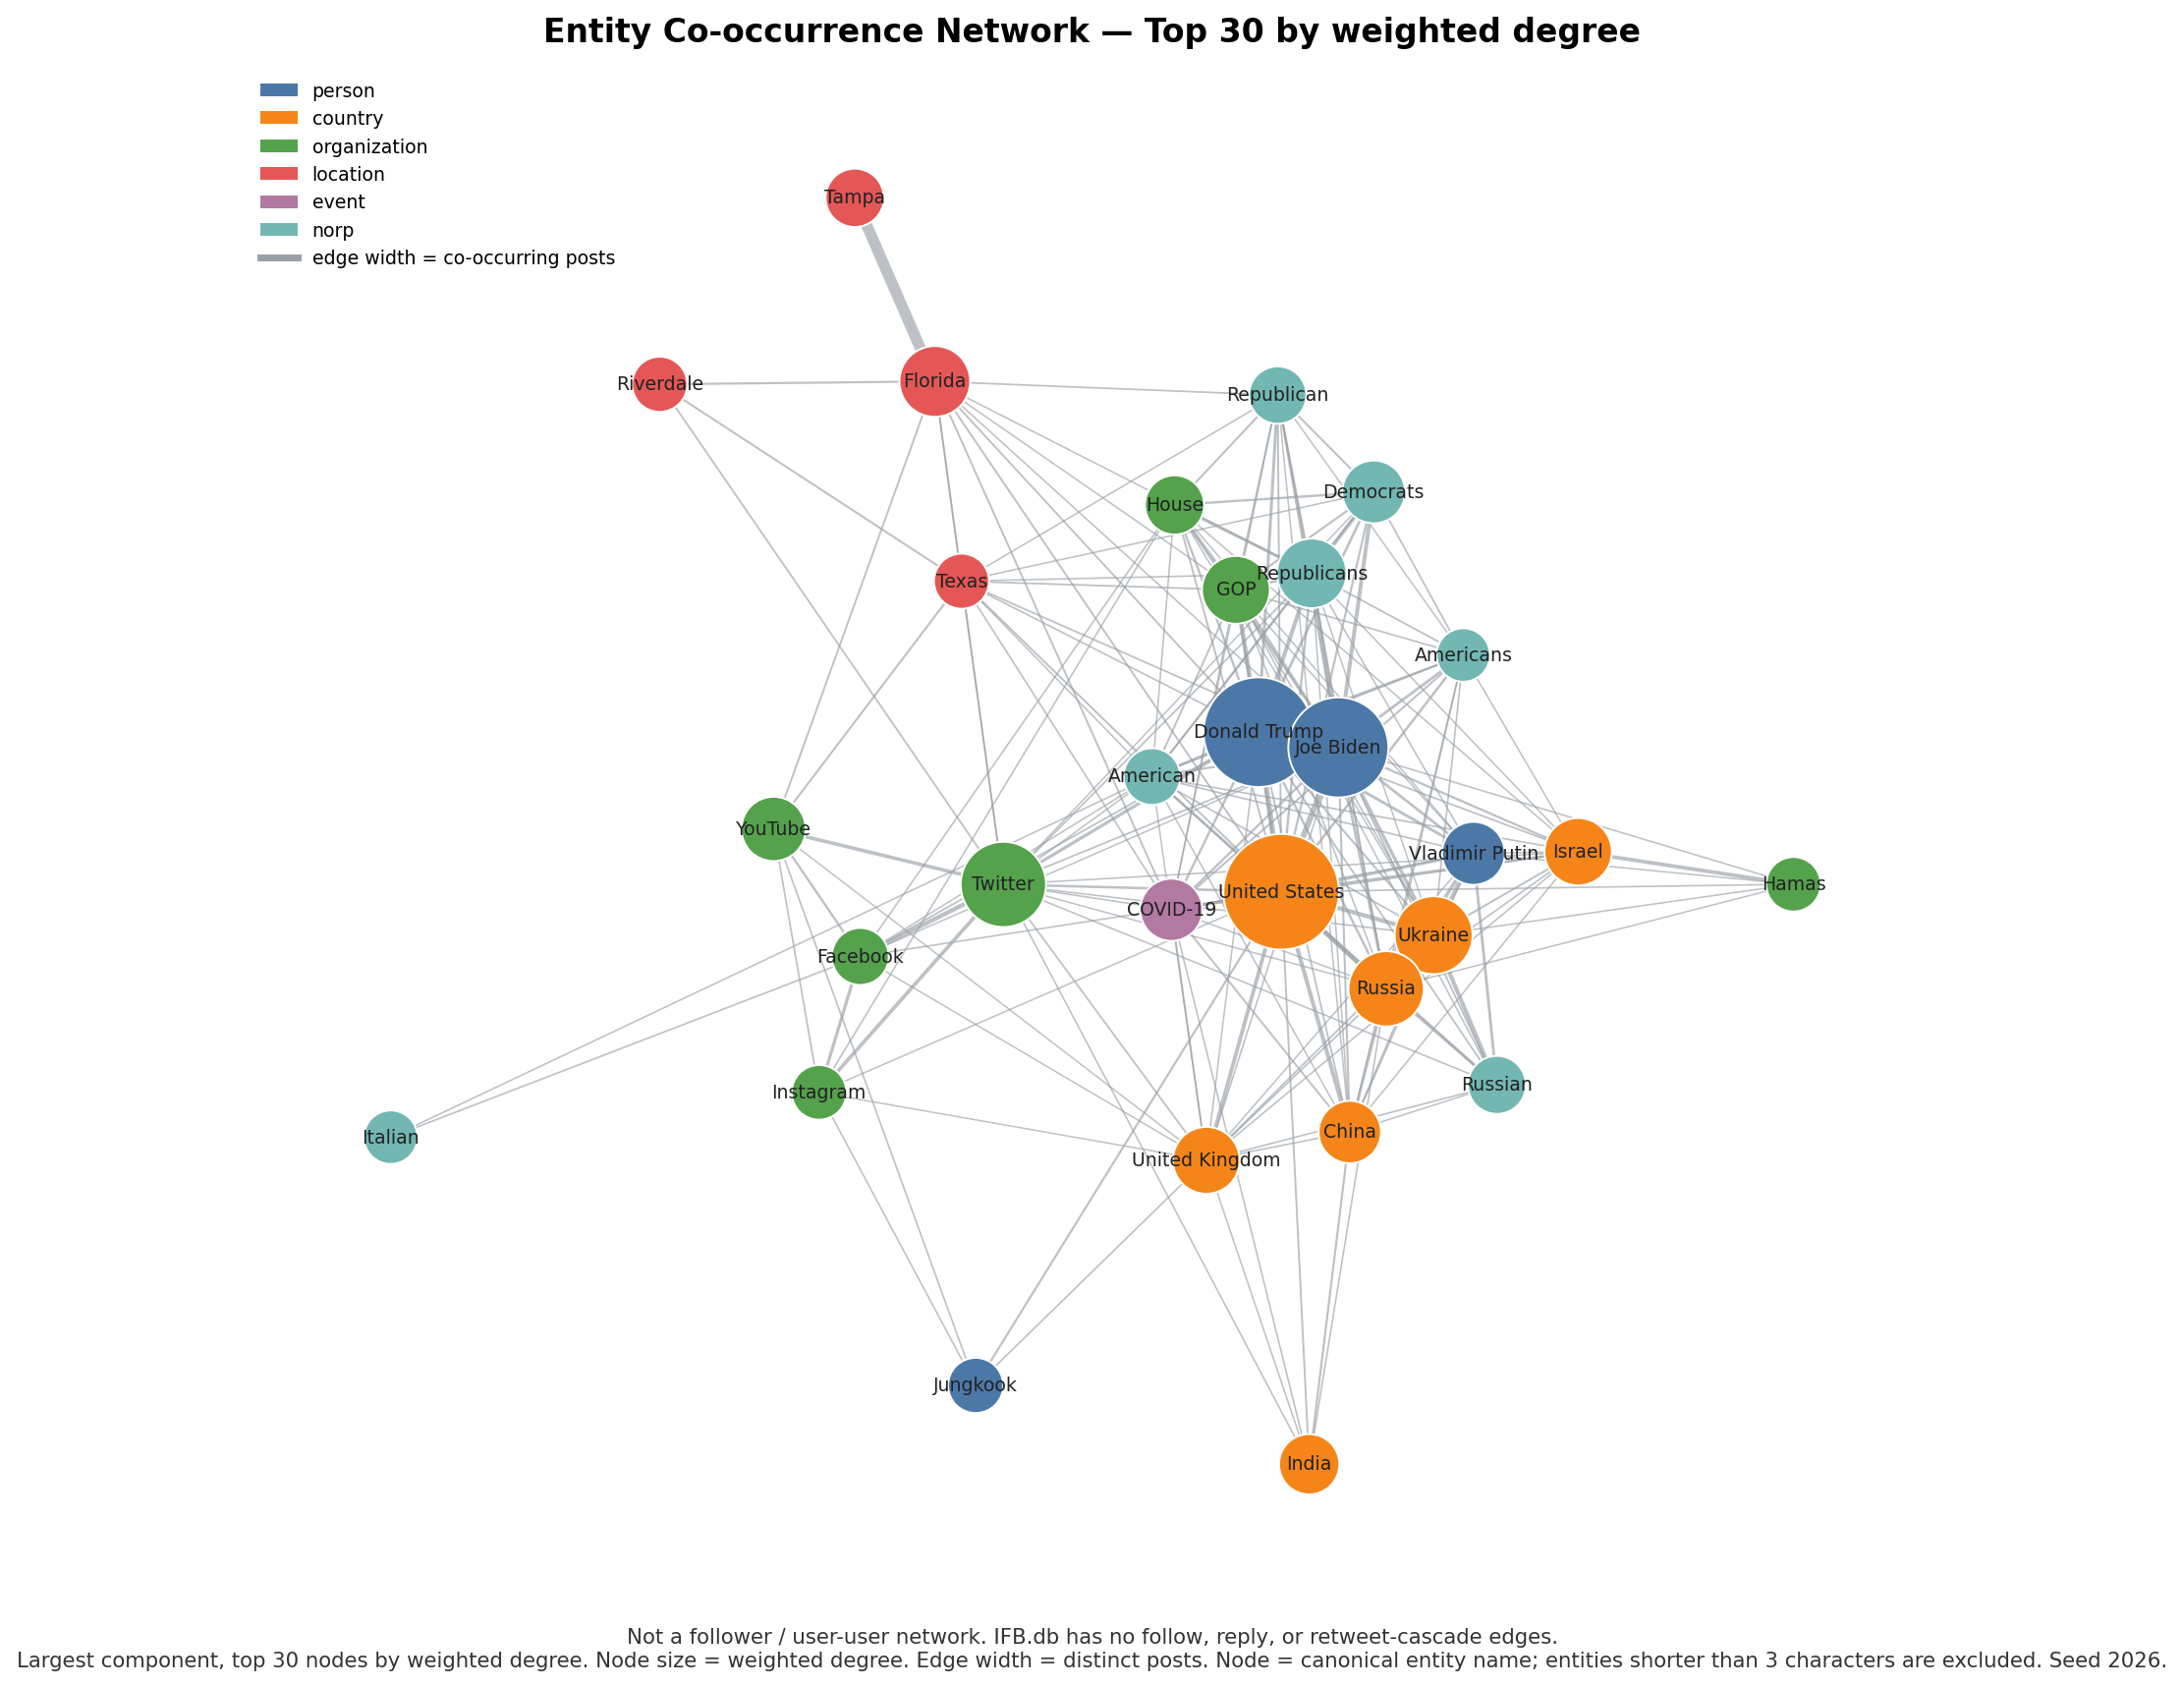

In [2]:
edges = pd.read_csv(OUT / "entity_network_edges.csv", encoding="utf-8-sig")
nodes = pd.read_csv(OUT / "entity_network_nodes.csv", encoding="utf-8-sig")
summary = pd.read_csv(OUT / "entity_network_summary.csv", encoding="utf-8-sig")
metrics = pd.read_csv(OUT / "entity_network_metrics.csv", encoding="utf-8-sig")
display(summary)
print("edge rows", len(edges), "node rows", len(nodes))
comb = summary[summary["graph"] == "combined_min_edge"].iloc[0]
assert int(float(comb["n_edges"])) == len(edges)
assert int(float(comb["n_nodes"])) == len(nodes)
assert int((edges["entity_a"] == edges["entity_b"]).sum()) == 0
keys = [tuple(sorted([a, b])) for a, b in zip(edges["entity_a"], edges["entity_b"])]
assert len(keys) == len(set(keys))
assert ((edges["entity_a"].str.len() >= 3) & (edges["entity_b"].str.len() >= 3)).all()
assert not set(nodes["entity"]).intersection({"CW", "VN", "&"})
deg_sum = pd.to_numeric(metrics["degree"], errors="coerce").sum()
print("sum(degree)/2", deg_sum / 2)
assert int(deg_sum / 2) == len(edges)
display(edges.head(8))
display(Image(filename=str(OUT / "entity_network_graph.png")))
print("DONE network verification")
